<a href="https://colab.research.google.com/github/thegurdian/ML/blob/main/transformer_based_sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("First review:", X_train[0])
print("First label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training samples: 25000
Testing samples: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5,

In [ ]:
max_length = 200

X_train = pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print(X_train.shape)
print(X_test.shape)

(25000, 200)
(25000, 200)


In [ ]:
class TokenAndPositionEmbedding(tf.keras.layers.Layer):

    def __init__(self, max_length, vocab_size, embed_dim):
        super().__init__()

        self.token_embedding = tf.keras.layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim,
            mask_zero=True
        )

        self.position_embedding = tf.keras.layers.Embedding(
            input_dim=max_length,
            output_dim=embed_dim
        )

    def call(self, inputs):

        sequence_length = tf.shape(inputs)[-1]

        positions = tf.range(
            start=0,
            limit=sequence_length,
            delta=1
        )

        token_embeddings = self.token_embedding(inputs)

        position_embeddings = self.position_embedding(positions)

        return token_embeddings + position_embeddings

In [ ]:
class TransformerBlock(tf.keras.layers.Layer):

    def __init__(self, embed_dim, num_heads, ff_dim, dropout_rate=0.1):

        super().__init__()

        self.attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(ff_dim, activation="relu"),
            tf.keras.layers.Dense(embed_dim)
        ])

        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)

        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = tf.keras.layers.Dropout(dropout_rate)

        self.dropout2 = tf.keras.layers.Dropout(dropout_rate)

    def call(self, inputs, training=False):

        x, token_ids = inputs

        valid_tokens = tf.not_equal(token_ids, 0)

        attention_mask = valid_tokens[:, tf.newaxis, :]

        # Multi-Head Self-Attention
        attention_output = self.attention(
            query=x,
            key=x,
            value=x,
            attention_mask=attention_mask
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        # Residual Connection + Layer Normalization
        out1 = self.layernorm1(x + attention_output)

        # Feed Forward Network
        ffn_output = self.ffn(out1)

        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        # Residual Connection + Layer Normalization
        output = self.layernorm2(out1 + ffn_output)

        return output

In [ ]:
class MaskedAveragePooling(tf.keras.layers.Layer):

    def call(self, inputs):

        x, token_ids = inputs

        mask = tf.cast(token_ids != 0, x.dtype)

        mask = tf.expand_dims(mask, axis=-1)

        summed = tf.reduce_sum(x * mask, axis=1)

        count = tf.reduce_sum(mask, axis=1)

        return summed / tf.maximum(count, 1.0)

In [ ]:
from tensorflow.keras import layers, Model

# Hyperparameters
embed_dim = 64
num_heads = 4
ff_dim = 128

inputs = layers.Input(shape=(max_length,), dtype="int32")

# 1. Embedding
x = TokenAndPositionEmbedding(
    max_length,
    vocab_size,
    embed_dim
)(inputs)

# 2. Transformer Encoder
x = TransformerBlock(
    embed_dim,
    num_heads,
    ff_dim
)([x, inputs])

# 3. Pooling
x = MaskedAveragePooling()([x, inputs])

# 4. Classification layers
x = layers.Dropout(0.3)(x)

x = layers.Dense(64, activation="relu")(x)

x = layers.Dropout(0.3)(x)

# 5. Output
outputs = layers.Dense(1, activation="sigmoid")(x)

# Complete model
model = Model(inputs=inputs, outputs=outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_and_position… │ (None, 200, 64)   │    652,800 │ input_layer[0][0] │
│ (TokenAndPositionE… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block   │ (None, 200, 64)   │     33,472 │ token_and_positi… │
│ (TransformerBlock)  │                   │            │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masked_average_poo… │ (None, 64)        │          0 │ transformer_bloc… │
│ (MaskedAveragePool… │                   │            │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ masked_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      4,160 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         65 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 690,497 (2.63 MB)

 Trainable params: 690,497 (2.63 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=5,
    validation_split=0.2
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 121s 375ms/step - accuracy: 0.7895 - loss: 0.4320 - val_accuracy: 0.8412 - val_loss: 0.3495
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 107s 341ms/step - accuracy: 0.9004 - loss: 0.2521 - val_accuracy: 0.8680 - val_loss: 0.3169
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 339ms/step - accuracy: 0.9212 - loss: 0.2033 - val_accuracy: 0.8652 - val_loss: 0.3346
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 135s 317ms/step - accuracy: 0.9396 - loss: 0.1603 - val_accuracy: 0.8584 - val_loss: 0.3787
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 314ms/step - accuracy: 0.9439 - loss: 0.1471 - val_accuracy: 0.8432 - val_loss: 0.4583


In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 36s 46ms/step - accuracy: 0.8212 - loss: 0.5173
Test Loss: 0.5172632336616516
Test Accuracy: 0.8212400078773499


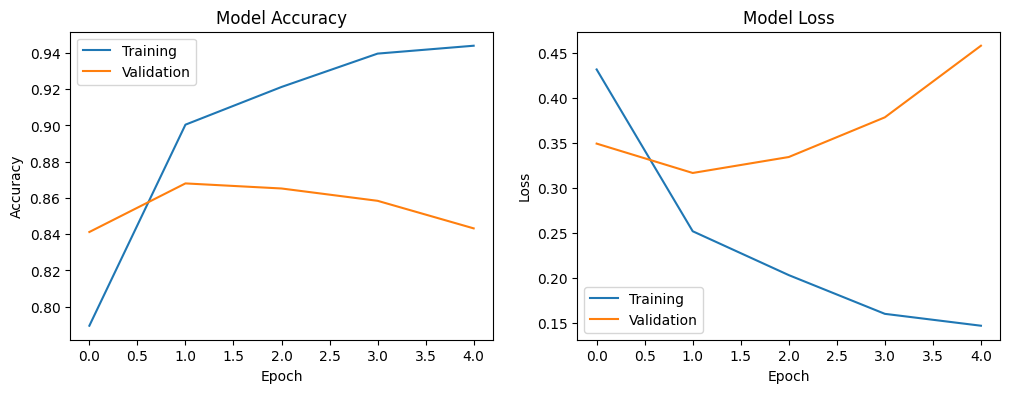

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [ ]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

word_index = imdb.get_word_index()


def encode_review(review):

    words = text_to_word_sequence(review)

    sequence = [1]  # Start token

    for word in words:

        index = word_index.get(word)

        if index is None or index + 3 >= vocab_size:
            sequence.append(2)  # Unknown token

        else:
            sequence.append(index + 3)

    return sequence

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step


In [ ]:
def predict_review(review):

    sequence = encode_review(review)

    padded_review = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    prediction = model.predict(padded_review, verbose=0)[0][0]

    if prediction >= 0.5:
        print("Sentiment: POSITIVE")
    else:
        print("Sentiment: NEGATIVE")

    print("Positive probability:", round(float(prediction), 4))

In [ ]:
predict_review(
    "This movie was fantastic. The acting was amazing and I loved it."
)

Sentiment: POSITIVE
Positive probability: 0.9993


In [ ]:
predict_review(
    "This movie was boring. The story was terrible and I hated it."
)

Sentiment: NEGATIVE
Positive probability: 0.0015


In [ ]:
model.save("transformer_sentiment_model.keras")

In [ ]:
loaded_model = tf.keras.models.load_model(
    "transformer_sentiment_model.keras",
    custom_objects={
        "TokenAndPositionEmbedding": TokenAndPositionEmbedding,
        "TransformerBlock": TransformerBlock,
        "MaskedAveragePooling": MaskedAveragePooling
    }
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'token_and_position_embedding_2', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'transformer_block_2', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


In [ ]:
class TokenAndPositionEmbedding(tf.keras.layers.Layer):
    def __init__(self, max_length, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.max_length = max_length
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.token_embedding = tf.keras.layers.Embedding(
            input_dim=vocab_size, output_dim=embed_dim, mask_zero=True
        )
        self.position_embedding = tf.keras.layers.Embedding(
            input_dim=max_length, output_dim=embed_dim
        )

    def call(self, inputs):
        sequence_length = tf.shape(inputs)[-1]
        positions = tf.range(start=0, limit=sequence_length, delta=1)
        token_embeddings = self.token_embedding(inputs)
        position_embeddings = self.position_embedding(positions)
        return token_embeddings + position_embeddings

    def get_config(self):
        config = super().get_config()
        config.update({
            "max_length": self.max_length,
            "vocab_size": self.vocab_size,
            "embed_dim": self.embed_dim,
        })
        return config

class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout_rate = dropout_rate
        self.attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads
        )
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(ff_dim, activation="relu"),
            tf.keras.layers.Dense(embed_dim)
        ])
        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = tf.keras.layers.Dropout(dropout_rate)
        self.dropout2 = tf.keras.layers.Dropout(dropout_rate)

    def call(self, inputs, training=False):
        x, token_ids = inputs
        valid_tokens = tf.not_equal(token_ids, 0)
        attention_mask = valid_tokens[:, tf.newaxis, :]
        attention_output = self.attention(
            query=x, key=x, value=x, attention_mask=attention_mask
        )
        attention_output = self.dropout1(attention_output, training=training)
        out1 = self.layernorm1(x + attention_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "ff_dim": self.ff_dim,
            "dropout_rate": self.dropout_rate,
        })
        return config

class MaskedAveragePooling(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, inputs):
        x, token_ids = inputs
        mask = tf.cast(token_ids != 0, x.dtype)
        mask = tf.expand_dims(mask, axis=-1)
        summed = tf.reduce_sum(x * mask, axis=1)
        count = tf.reduce_sum(mask, axis=1)
        return summed / tf.maximum(count, 1.0)

loaded_model = tf.keras.models.load_model(
    "transformer_sentiment_model.keras",
    custom_objects={
        "TokenAndPositionEmbedding": TokenAndPositionEmbedding,
        "TransformerBlock": TransformerBlock,
        "MaskedAveragePooling": MaskedAveragePooling
    }
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'token_and_position_embedding_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'transformer_block_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
